Figures, Axes, and Subplots
At this point, you've seen and had some practice with some basic plotting functions using matplotlib and seaborn. The previous page introduced something a little bit new: creating two side-by-side plots through the use of matplotlib's subplot()(opens in a new tab) function. If you have any questions about how that or the figure()(opens in a new tab) function worked, then read on. This page will discuss the basic structure of visualizations using matplotlib and how subplots work in that structure.

The base of visualization in matplotlib is a Figure(opens in a new tab) object. Contained within each Figure will be one or more Axes(opens in a new tab) objects, each Axes object containing a number of other elements that represent each plot. In the earliest examples, these objects have been created implicitly. Let's say that the following expression is run inside a Jupyter notebook to create a histogram:

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb
import numpy as np

pokemon = pd.read_csv('./bar_chart_datasets/pokemon.csv')

In [3]:
pokemon.head(10)

,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65
5,6,charizard,1,1.7,90.5,240,fire,flying,78,84,78,100,109,85
6,7,squirtle,1,0.5,9.0,63,water,NaN,44,48,65,43,50,64
7,8,wartortle,1,1.0,22.5,142,water,NaN,59,63,80,58,65,80
8,9,blastoise,1,1.6,85.5,239,water,NaN,79,83,100,78,85,105
9,10,caterpie,1,0.3,2.9,39,bug,NaN,45,30,35,45,20,20


In [4]:
pokemon['weight'].describe()

count    807.000000
mean      61.771128
std      111.519355
min        0.100000
25%        9.000000
50%       27.000000
75%       63.000000
max      999.900000
Name: weight, dtype: float64

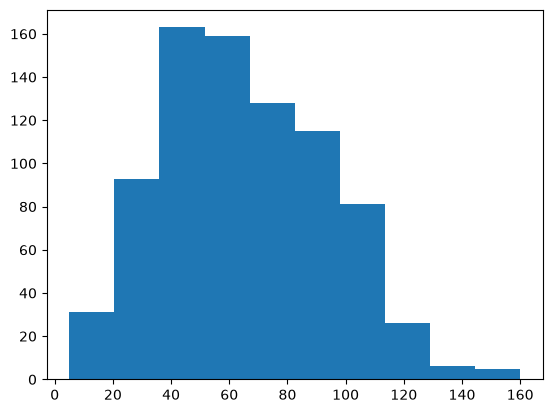

In [5]:
plt.hist(data=pokemon, x='speed')
plt.show()

Since we don't have a Figure area to plot inside, Python first creates a Figure object. And since the Figure doesn't start with any Axes to draw the histogram onto, an Axes object is created inside the Figure. Finally, the histogram is drawn within that Axes.

1. A Figure is created. There was no canvas, so Python makes one.
2. An Axes is created inside it. The new Figure has no chart area, so Python adds one.
3. The histogram is drawn on that Axes.

This hierarchy of objects is useful to know about so that we can take more control over the layout and aesthetics of our plots. One alternative way we could have created the histogram is to explicitly set up the Figure and Axes like this

Example 2. Demonstrate figure.add_axes() and axes.hist()

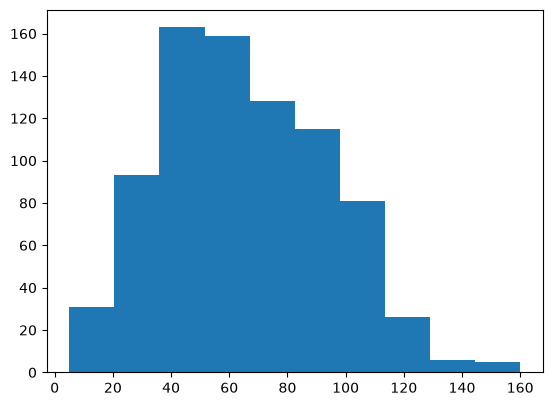

In [6]:
# Create a new figure

fig = plt.figure()

# The argument of add_axes represents the dimensions [left, bottom, width, height] of the new axes. 
# All quantities are in fractions of figure width and height.

ax = fig.add_axes([.125, .125, .775, .755])
ax.hist(data=pokemon, x='speed');

fig = plt.figure() creates a Figure and saves it in the variable fig, so you can talk to that exact Figure later.

fig.add_axes([left, bottom, width, height]) adds one Axes (one chart area) to that Figure and places it by hand. The four numbers are all fractions of the Figure, from 0 to 1:

1. left: how far from the figure’s left edge the chart starts
2. bottom: how far up from the bottom edge it starts
3. width and height: how much of the figure it covers

figure()(opens in a new tab) creates a new Figure object, a reference to which has been stored in the variable fig. One of the Figure methods is .add_axes()(opens in a new tab), which creates a new Axes object in the Figure. The method requires one list as argument specifying the dimensions of the Axes: the first two elements of the list indicate the position of the lower-left hand corner of the Axes (in this case one quarter of the way from the lower-left corner of the Figure) and the last two elements specifying the Axes width and height, respectively. We refer to the Axes in the variable ax. Finally, we use the Axes method .hist()(opens in a new tab) just like we did before with plt.hist().

To use Axes objects with seaborn, seaborn functions usually have an "ax" parameter to specify upon which Axes a plot will be drawn.
Example 2. Use axes with seaborn.countplot()

<Axes: xlabel='generation_id', ylabel='count'>

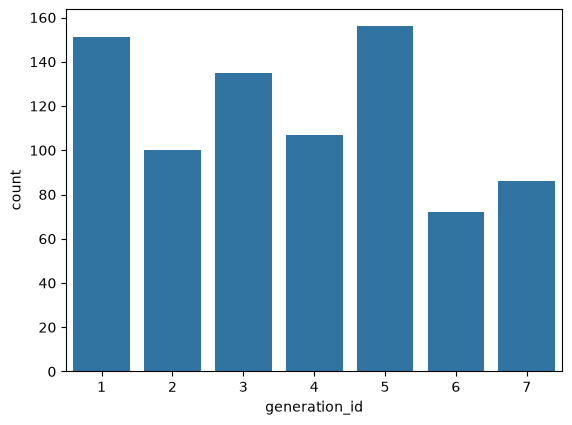

In [7]:
fig = plt.figure()

ax = fig.add_axes([.125, .125, .775, .755])

sb.countplot(data=pokemon, x='generation_id', ax=ax)

In the above two cases, there was no purpose to explicitly go through the Figure and Axes creation steps. And indeed, in most cases, you can just use the basic matplotlib and seaborn functions as is. Each function targets a Figure or Axes, and they'll automatically target the most recent Figure or Axes worked with. As an example of this, let's review in detail how subplot()(opens in a new tab) was used on the Histograms page:

Example 3. Sub-plots

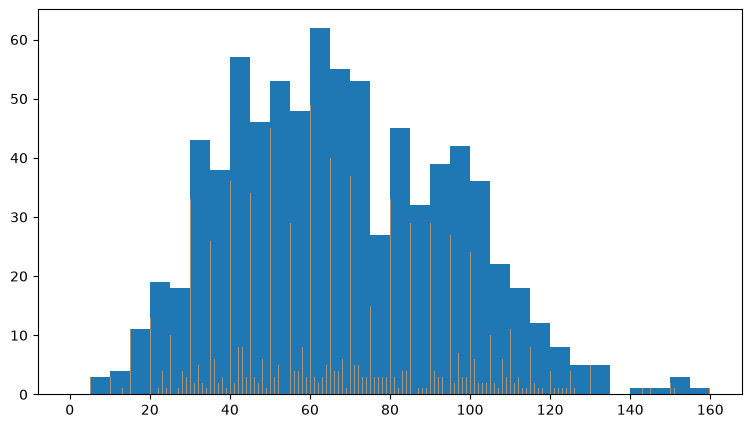

In [8]:
plt.figure(figsize=[20, 5])

plt.subplot(1, 2, 1)
bins = np.arange(0, pokemon['speed'].max()+5, 5)
plt.hist(data=pokemon, x='speed', bins=bins)

#plt.subplot(1, 2, 2)
bins = np.arange(0, pokemon['speed'].max()+1/4, 1/4)
plt.hist(data=pokemon, x='speed', bins=bins)

plt.show()

First of all, plt.figure(figsize = [20, 5])creates a new Figure, with the "figsize" argument setting the width and height of the overall figure to 20 inches by 5 inches, respectively. Even if we don't assign any variable to return the function's output, Python will still implicitly know that further plotting calls that need a Figure will refer to that Figure as the active one.

Then, plt.subplot(1, 2, 1) creates a new Axes in our Figure, its size determined by the subplot() function arguments. The first two arguments says to divide the figure into one row and two columns, and the third argument says to create a new Axes in the first slot. Slots are numbered from left to right in rows from top to bottom. Note in particular that the index numbers start at 1 (rather than the usual Python indexing starting from 0). (You'll see the indexing a little better in the example at the end of the page.) Again, Python will implicitly set that Axes as the current Axes, so when the plt.hist() call comes, the histogram is plotted in the left-side subplot.

Finally, plt.subplot(1, 2, 2) creates a new Axes in the second subplot slot, and sets that one as the current Axes. Thus, when the next plt.hist() call comes, the histogram gets drawn in the right-side subplot.

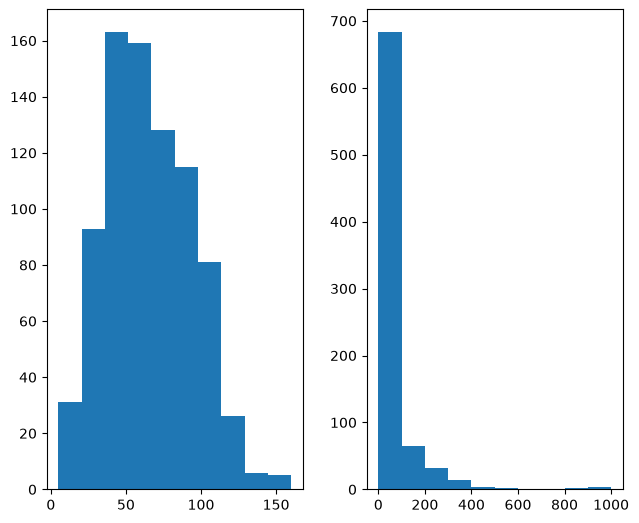

In [9]:
fig = plt.figure()

ax1 = fig.add_axes([0, 0, 0.4, 1])
ax2 = fig.add_axes([0.5, 0, 0.4, 1])

ax1.hist(data=pokemon, x='speed')
ax2.hist(data=pokemon, x='weight')

plt.show()

Additional Techniques
To close this page, we'll quickly run through a few other ways of dealing with Axes and subplots. The techniques above should suffice for basic plot creation, but you might want to keep the following in the back of your mind as additional tools to break out as needed.

If you don't assign Axes objects as they're created, you can retrieve the current Axes using ax = plt.gca()(opens in a new tab), or you can get a list of all Axes in a Figure fig by using axes = fig.get_axes()(opens in a new tab). As for creating subplots, you can use fig.add_subplot()(opens in a new tab) in the same way as plt.subplot() above. If you already know that you're going to be creating a bunch of subplots, you can use the plt.subplots()(opens in a new tab) function:

Example 4. Demonstrate pyplot.sca() and pyplot.text() to generate a grid of subplots

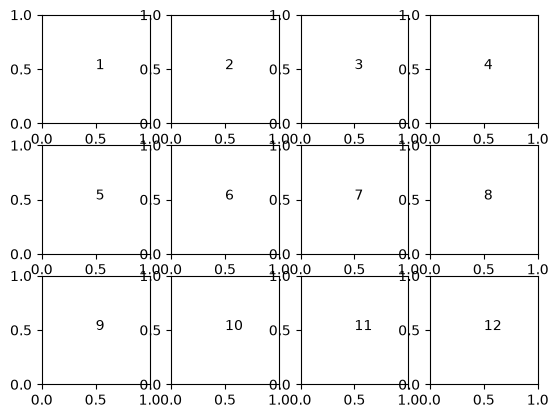

In [15]:
fig, axes = plt.subplots(3, 4) #grid of 3x4 subplots
axes = axes.flatten() #reshape from 3x4 array into 12-element vector

for i in range(12):
    plt.sca(axes[i]) #set the current axes
    plt.text(0.5, 0.5, i+1) # print conventional subplot index number to middle of axes
plt.show()